### **Dataset Selection and Final Project Planning Lab Week 3 Part 2.**

Student Name: Aeran Lee

Step 1: Data selection
---
*Dataset:*
Cirrhosis Patient Survival Prediction dataset from UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/878/cirrhosis+patient+survival+prediction+dataset-1)

*Description:*
This dataset contains data from 418 patients with cirrhosis. It includes variable that can be used to examine patient outcomes and explore potential predictors of mortality.

*Notebook Purpose:*
The purpose of this notebook is to examine and justify the selection of a dataset by exploring its structure, variables, and overal data quality in preparation for implementing a complete analytical pipeline for the final project.

*Reason for data selection:*
I selected this dataset to evaluate whether demographic, clinical, and laboratory variables can predict whether death was observed during follow-up among patients with primary biliary cirrhosis.

The dataset include multiple clinical variables that may be associated with patient outcomes. I am particularly interested in identifying which variables are most strongly associated with mortality among patients with cirrhosis. By applying machine learning methods, I hope to identify important predictors of observed mortality and better understand how clinical data can be used for mortality risk prediction.  

*Project criteria:*
The primary outcome variable is Status, which includes three categories: D (death), C (censored), and CL (censored due to liver transplantation).

To satisfy the assignment requirement for binary classification, I plan to combine C and CL into a single category representing patients without observed death during follow - up, while D will represent patients with observed death. However, censoring does not necessarily indicate survival, and this distiction will be acknowledged as a limitation of the binary classficastion approach.

The dataset contains 418 observations and 17 variables, satisfying the assignment requirements of at least 300 observations and predictor variables, subject to confirmation of the number of usable predictors after data processing.

In [81]:
# @title Step 2: Dataset Exploration

from google.colab import files
import pandas as pd
import io
from pathlib import Path

# Update dataset
uploaded = files.upload()

# Ensure exactly one file is uploaded
if len(uploaded) !=1:
  raise ValueError("Please upload exactly one data file.")

# Identify uploaded file
filename = next(iter(uploaded))
extension = Path(filename).suffix.lower()
file_data = io.BytesIO(uploaded[filename])

# Load data based on file format
if extension in [".csv", ".tsv", ".txt"]:
    # Automatically detect the delimiter.
    df = pd.read_csv(file_data, sep=None, engine="python")

elif extension in [".xlsx", ".xls"]:
    # Load the first worksheet.
    df = pd.read_excel(file_data)

elif extension == ".json":
    df = pd.read_json(file_data)

elif extension == ".parquet":
    df = pd.read_parquet(file_data)

else:
    raise ValueError(
        f"'{extension}' files require a different reader. "
        "Supported format: CSV, TSV, TXT, XLSX, XLS, JSON, and Parquet."
    )

# Verify succesful loading
print(f"Succesfully loaded: {filename}")
print(f"Rows: {df.shape[0]} | Columns {df.shape[1]}")

display(df.head())


Saving cirrhosis.csv to cirrhosis (7).csv
Succesfully loaded: cirrhosis (7).csv
Rows: 418 | Columns 20


,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,1,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,2,4500,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,3,1012,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,4,1925,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,5,1504,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0


In [82]:
# @title Step 2-A: Inspect Dataset Variables

attribute_list = list(df.columns)
print("Variables in the dataset:")
print("")
print(attribute_list)

Variables in the dataset:

['ID', 'N_Days', 'Status', 'Drug', 'Age', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage']


In [83]:
# @title Stsep 2-B: Check Dataset Dimension (Rows and Columns)

print("Number of rows and columns")
print("")
df.shape # (rows, colums)

Number of rows and columns



(418, 20)

In [84]:
# @title Step 2-C: Inspect Dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             418 non-null    int64  
 1   N_Days         418 non-null    int64  
 2   Status         418 non-null    object 
 3   Drug           312 non-null    object 
 4   Age            418 non-null    int64  
 5   Sex            418 non-null    object 
 6   Ascites        312 non-null    object 
 7   Hepatomegaly   312 non-null    object 
 8   Spiders        312 non-null    object 
 9   Edema          418 non-null    object 
 10  Bilirubin      418 non-null    float64
 11  Cholesterol    284 non-null    float64
 12  Albumin        418 non-null    float64
 13  Copper         310 non-null    float64
 14  Alk_Phos       312 non-null    float64
 15  SGOT           312 non-null    float64
 16  Tryglicerides  282 non-null    float64
 17  Platelets      407 non-null    float64
 18  Prothrombi

In [85]:
# @title Step 2-D: Convert Data Types and Age Units

# Convert ID and N_Days to Object
df["ID"] = df["ID"].astype("object")
df["N_Days"] = df["N_Days"].astype("object")

# Convert Age from days to years
df["Age"] = df["Age"]/365.25

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             418 non-null    object 
 1   N_Days         418 non-null    object 
 2   Status         418 non-null    object 
 3   Drug           312 non-null    object 
 4   Age            418 non-null    float64
 5   Sex            418 non-null    object 
 6   Ascites        312 non-null    object 
 7   Hepatomegaly   312 non-null    object 
 8   Spiders        312 non-null    object 
 9   Edema          418 non-null    object 
 10  Bilirubin      418 non-null    float64
 11  Cholesterol    284 non-null    float64
 12  Albumin        418 non-null    float64
 13  Copper         310 non-null    float64
 14  Alk_Phos       312 non-null    float64
 15  SGOT           312 non-null    float64
 16  Tryglicerides  282 non-null    float64
 17  Platelets      407 non-null    float64
 18  Prothrombi

In [86]:
# @title Step 2-E: Generate Descriptive Statistics and Variable Summary

# Describe all columns
summary = df.describe(include='all').T

# Insert formatted variable name + data type
summary.insert(
    0,
    'Variable',
    [f"<b>{col}</b><br><span style = 'font-weight:normal; font-size:smaller;'>[{df[col].dtype}]</span>" for col in summary.index]
)

# Reset index to clean up formatting
summary.reset_index(drop=True, inplace=True)

# Format numeric columns to 3 decimal places only
styled_summary = (
    summary.style
    .format(precision=3, na_rep="NA") # Format numbers to 3 decimals
    .set_table_styles([
        {'selector': 'th', 'props': [('font-weight', 'bold'), ('text-aligh', 'center')]},
        {'selector': 'td', 'props': [('text-aligh', 'center')]}
    ])
    .hide(axis='index') #remove default row index
)

styled_summary

Variable,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID[object],418.000,418.000,418.000,1.000,NA,NA,NA,NA,NA,NA,NA
N_Days[object],418.000,399.000,41.000,2.000,NA,NA,NA,NA,NA,NA,NA
Status[object],418,3,C,232,NA,NA,NA,NA,NA,NA,NA
Drug[object],312,2,D-penicillamine,158,NA,NA,NA,NA,NA,NA,NA
Age[float64],418.000,NA,NA,NA,50.742,10.447,26.278,42.832,51.001,58.241,78.439
Sex[object],418,2,F,374,NA,NA,NA,NA,NA,NA,NA
Ascites[object],312,2,N,288,NA,NA,NA,NA,NA,NA,NA
Hepatomegaly[object],312,2,Y,160,NA,NA,NA,NA,NA,NA,NA
Spiders[object],312,2,N,222,NA,NA,NA,NA,NA,NA,NA
Edema[object],418,3,N,354,NA,NA,NA,NA,NA,NA,NA


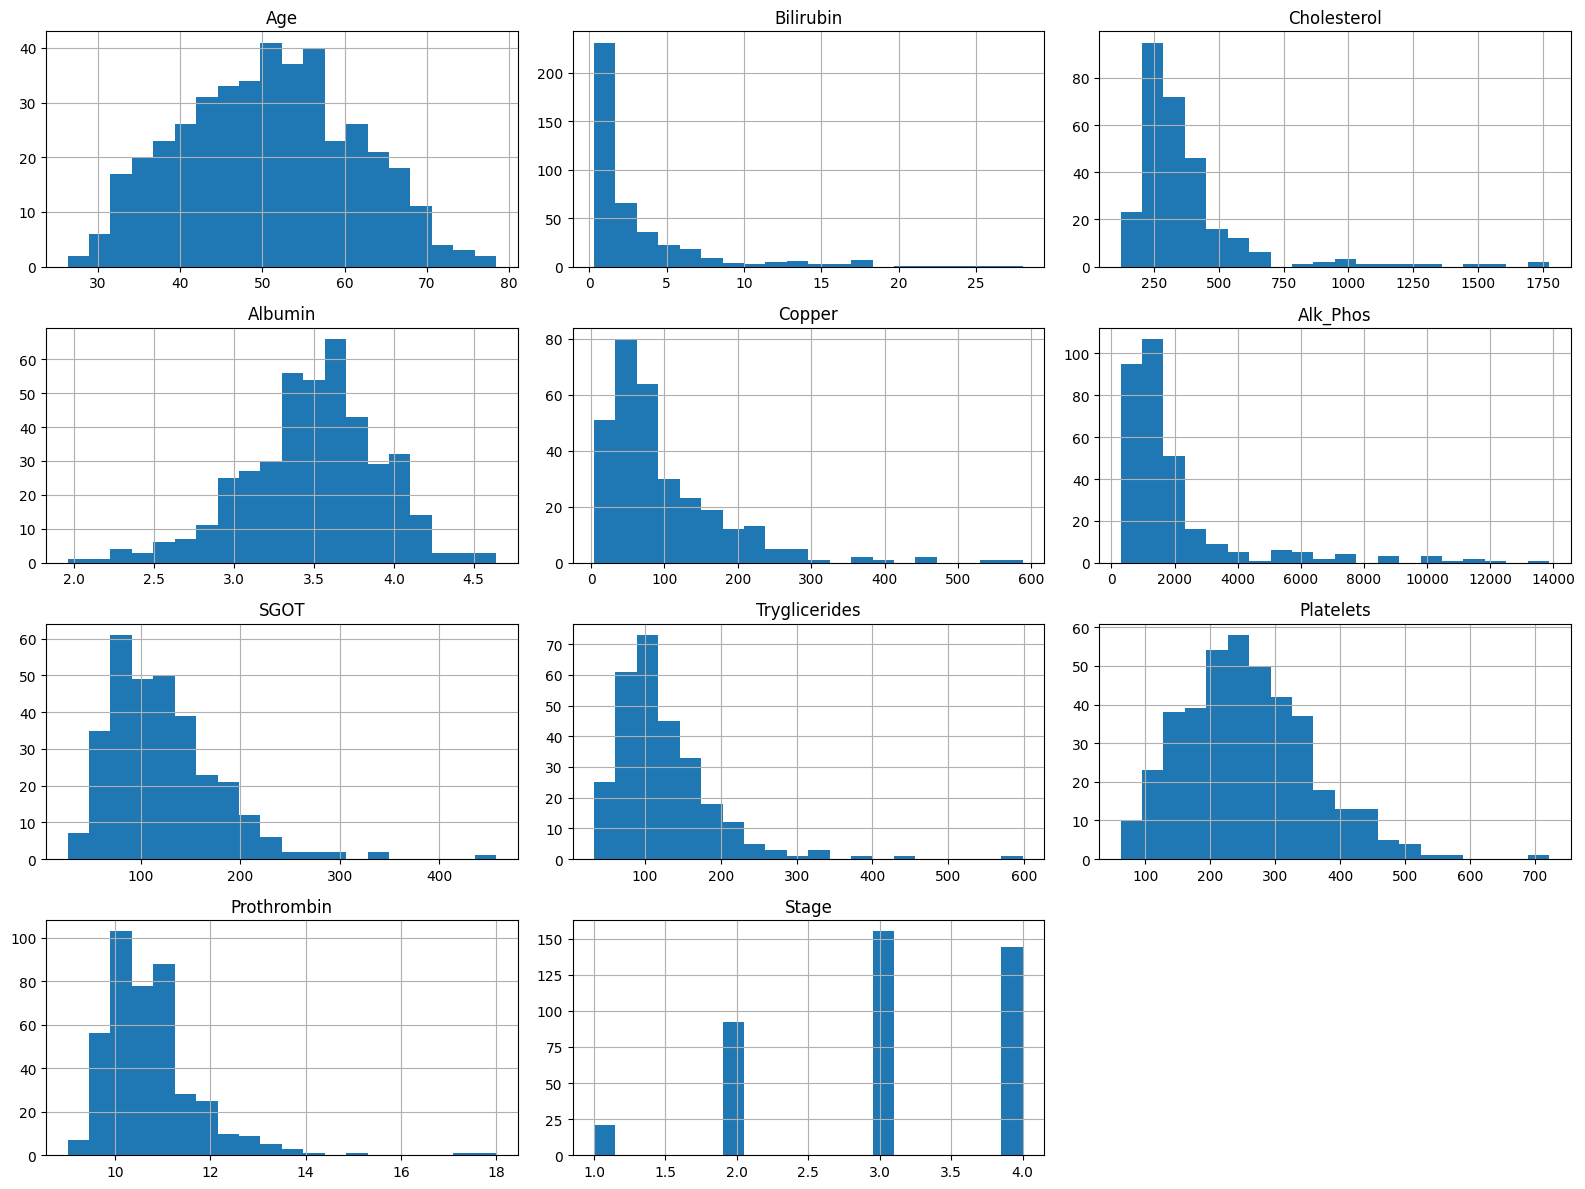

In [87]:
# @title Step 2-F: exploratory visualization - 1: Generate histograms for all numerical variables
import seaborn as sns
import matplotlib.pyplot as plt

df.hist(figsize=(16,12), bins=20)
plt.tight_layout()
plt.show()

Death_Outcome
Censored    257
Death       161
Name: count, dtype: int64


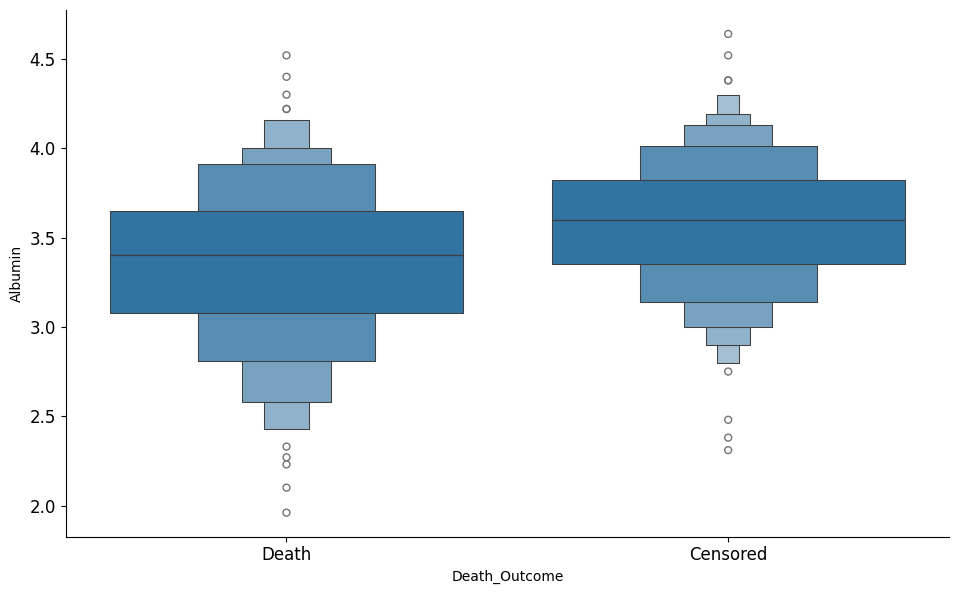

In [88]:
# @title Step 2-Fb: Exploratory visualization 2: Create Binary Outcome and Categorical plot

import seaborn as sns
import matplotlib.pyplot as plt

# Create binary mortality outcome
# 1 = Death observed
# 0 = No death observed during follow-up

df["Death_Outcome"] = df["Status"].map({
    "D": "Death",
    "C": "Censored",
    "CL": "Censored"
})

# Verify the distribution
print(df["Death_Outcome"].value_counts(dropna=False))


# Define the plot variables
x_var = "Death_Outcome"
y_var = "Albumin"

# Create the plot
g = sns.catplot(x=x_var, y=y_var, data=df, kind='boxen', height=6, aspect=1.6);

# Dynamically set axis labels
g.set_axis_labels(x_var, y_var)
g.set_titles("{col_name}")

# Optionally set font size
g.set(xlabel=x_var, ylabel=y_var)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

In [89]:
# @title Step 3: Data Qualtiy Assessement
# $title Step 3-A: Automatically Identify Missing Values in Numeric Predictors

target_variable = "Death_outcome"

# Automatically identify numeric predictors.
numeric_predictors = df.select_dtypes(include="number").columns
numeric_predictors = numeric_predictors.drop(
    target_variable, errors="ignore"
)

# Count missing values.
missing_counts = df[numeric_predictors].isna().sum()
predictors_with_missing = missing_counts[missing_counts > 0]

# Report missing values
if predictors_with_missing.empty:
    print("No missing values detected in numeric predictors.")
else:
    print("Numeric predictors requiring imputation:")
    display(predictors_with_missing.rename("Missing values").to_frame())

    print("\nMissing values identified but not yet imputed.")
    print("Imputation will be performed using training-set medians in the ML pipeline.")

Numeric predictors requiring imputation:


,Missing values
Cholesterol,134
Copper,108
Alk_Phos,106
SGOT,106
Tryglicerides,136
Platelets,11
Prothrombin,2
Stage,6



Missing values identified but not yet imputed.
Imputation will be performed using training-set medians in the ML pipeline.


In [90]:
# @title Step 3-B: Summarize Non-Missing and Missing Values by Variable

# Count non-null and missing responses
response_counts = df.count()
missing_counts = df.isnull().sum()

# Combine into one DataFrame
df_count = pd.DataFrame({
    'Variable': response_counts.index,
    '# of Responses': response_counts.values,
    '# Missing': missing_counts.values
})

# Display as styled table: bold headers and center-aligned values
df_count.style.set_table_styles([
    {'selector': 'th', 'props': [('font-weight', 'bold'), ('text-align', 'center')]},
    {'selector': 'td', 'props': [('text-align', 'center')]}
])

,Variable,# of Responses,# Missing
0,ID,418,0
1,N_Days,418,0
2,Status,418,0
3,Drug,312,106
4,Age,418,0
5,Sex,418,0
6,Ascites,312,106
7,Hepatomegaly,312,106
8,Spiders,312,106
9,Edema,418,0


**Data Quality Assessment**

1. Missing Values and Data Quality
The dataset contains 418 observations, with missing values identified in 12 variables. Triglycerides (282 missing), cholesterol (284 missing) have the highest percentages of missing data, followed by copper. Several other clinical variables, including ascietes, hepatomegaly, spiders, alkaline phosphatase, and SGOT, have 106 missing values. In contrast, the outcome variable (Death_outcome) has no missing observations.

2. Anticipated Preprocessing Steps
Missing numerical values will be handled using medican imputation, while missing categorical values will be handled using appropriate categorical imputation methods. Patient ID and N_Days will be excluded from the baseline prediction model to avoid using idenifiers and follow- up information predictors. Age has been converted from days to years for easier clinical interpretation. Categorical predictors will be encoded, and numerical predictors will be scaled as needed. Data preprocessing will be fitted using the training dataset to minimize data leakage.

3. Potential challenges
The relatively small sample size and substantial missingness in several clinical variables may affect model performance and generalizability. The repeated pattern of 106 missing observations across multiple variables suggests possible systematic missingness that requires further investigation. Skewed laboratory values and potential class imbalacne may also influence model performance.
Another liitation is the binary outcome definition. Combiming ceonsored patients and patients cencered due to liver transplatation into a single category does not account for differences in follow-up duration or the competing event of liver tranplantation. Therefore, the model will predict observed mortaility status rather than true survival probability.

# Step 4: Project Planning

*Proposed Prediction Problem: *
The goal of this project is to develop a binary classification machine learning model to predict whether death was observed during follow-up among patients with primary biliary cirrhosis. Demographic, clnical, and laboratry variables will be used to identify potential predictors associated with observed mortality.

*Target Variable*
The targe variable is `Death_Outcome`, derived from the origianal `Status`variable:


*   1 = Death: Death observed during follow - up (D).
*   0 = No observed Death: Censored (C) or censored due to livber transplantation (CL).

The binary classification approach meets the assignment requirements. However, censored observation do not necessarily indicate long-term survival, and the model will not account for differences in follow-up duration.

Cadidate Evaluation Metrics
ROC-AUC will be used as the primary evaluation metric to assess the model's ability to distinguish between patients with and without observed death during follow-up.

Additional evaluation metrics will include:


*   Recall(Sensitivity): Measures the proportion of patients with observed death correctly identified by the model.
*   Precision: Measure the proportion of pedicted death that were actually observed deaths.
*   F1-Score: Balances precision and recall.
*   Confusion Matrix: Summarizes tru positives, true negatives, false positives, and false negatives.

Given the clinical importance of identifying patients at increased risk of mortality, recall will be particularly important when evaluating model performance.










